# Project 3 — Divvy Ridership Forecasting
## Milestone check, Thursday 19 November 2026

**Team:** Taman Azad, Isaac Guttormson · **Course:** DSDA 310 Senior Seminar

**Operational decision this forecast serves:** an operations manager deciding how
many bikes to stage tomorrow morning. The target is therefore *total completed
rides per local calendar day, citywide* — the quantity that determines how much
fleet has to be in the street.

This notebook covers the five items due today:

1. Daily ridership table
2. Seasonal visualisation
3. Weather merge — **verified, not assumed**
4. Data-quality summary
5. Baseline plan

Run `python build_dataset.py` first; it writes everything this notebook reads.

In [1]:
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

# --- chart styling: one place, so every figure matches -----------------------
INK, INK2, MUTED = "#0b0b0b", "#52514e", "#898781"
GRID, AXIS, SURFACE = "#e1e0d9", "#c3c2b7", "#fcfcfb"
S1, S2, S3 = "#2a78d6", "#eb6834", "#1baf7a"   # blue, orange, aqua

mpl.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE,
    "savefig.facecolor": SURFACE,
    "font.family": "sans-serif", "font.size": 10,
    "axes.edgecolor": AXIS, "axes.linewidth": 0.8,
    "axes.labelcolor": INK2, "axes.titlecolor": INK,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.titlepad": 12, "axes.grid": True, "axes.axisbelow": True,
    "grid.color": GRID, "grid.linewidth": 0.8,
    "xtick.color": MUTED, "ytick.color": MUTED,
    "xtick.labelcolor": INK2, "ytick.labelcolor": INK2,
    "legend.frameon": False, "figure.dpi": 110,
})

def tidy(ax, ygrid=True):
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)
    ax.grid(axis="y" if ygrid else "x")
    ax.grid(axis="x" if ygrid else "y", visible=False)
    return ax

thousands = FuncFormatter(lambda v, _: f"{v:,.0f}")

daily = pd.read_csv("data/divvy_daily_merged.csv", parse_dates=["date"]) \
          .sort_values("date").reset_index(drop=True)
hourly = pd.read_csv("data/divvy_hourly_merged.csv", parse_dates=["hour_local"])

print(f"daily  {daily.shape[0]} rows x {daily.shape[1]} cols")
print(f"hourly {hourly.shape[0]} rows x {hourly.shape[1]} cols")
print(f"total rides CY2025: {daily.rides.sum():,}")

daily  365 rows x 23 cols
hourly 8759 rows x 22 cols
total rides CY2025: 5,552,941


---
## 1. Daily ridership table

Built by aggregating individual trips on **`started_at`**, floored to the local
Chicago hour and then rolled up to the local calendar date. Rides are keyed on
their own start timestamp, not on the file that shipped them — 1,075 rides in the
2025 archives start in a month other than their file's, and 53 rides in the
January file actually start on 2024-12-31 and are therefore **out of scope** for
calendar year 2025.

In [2]:
MONTHS = ["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"]

tbl = daily.groupby("month").agg(
    days=("date", "size"),
    rides=("rides", "sum"),
    avg_day=("rides", "mean"),
    peak_day=("rides", "max"),
    low_day=("rides", "min"),
    avg_temp_F=("temperature_2m", "mean"),
    wet_days=("precip_any", "sum"),
).reset_index()
tbl["share_%"] = 100 * tbl.rides / tbl.rides.sum()
tbl["casual_%"] = 100 * daily.groupby("month").casual.sum() / daily.groupby("month").rides.sum()
tbl["month"] = [MONTHS[m-1] for m in tbl.month]

show = tbl[["month","days","rides","share_%","avg_day","peak_day","low_day",
            "avg_temp_F","wet_days","casual_%"]]
display(show.style.format({
    "rides":"{:,.0f}","share_%":"{:.1f}","avg_day":"{:,.0f}","peak_day":"{:,.0f}",
    "low_day":"{:,.0f}","avg_temp_F":"{:.1f}","casual_%":"{:.1f}"}).hide(axis="index"))

print(f"CY2025 total            {daily.rides.sum():>12,}")
print(f"peak month              {tbl.loc[tbl.rides.idxmax(),'month']} "
      f"({tbl.rides.max():,})")
print(f"trough month            {tbl.loc[tbl.rides.idxmin(),'month']} "
      f"({tbl.rides.min():,})")
print(f"seasonal swing          {tbl.rides.max()/tbl.rides.min():.2f}x")
print(f"daily rides  median     {daily.rides.median():>12,.0f}")
print(f"             min / max  {daily.rides.min():,} / {daily.rides.max():,}")
print(f"             std dev    {daily.rides.std():>12,.0f}")
print(f"member / casual split   {100*daily.member.sum()/daily.rides.sum():.1f}% / "
      f"{100*daily.casual.sum()/daily.rides.sum():.1f}%")

month,days,rides,share_%,avg_day,peak_day,low_day,avg_temp_F,wet_days,casual_%
Jan,31,"138,651",2.5,"4,473","8,676","1,309",22.3,10,nan
Feb,28,"151,901",2.7,"5,425","10,106","2,511",26.2,13,17.4
Mar,31,"298,130",5.4,"9,617","19,782","3,530",42.9,14,18.3
Apr,30,"371,376",6.7,"12,379","19,030","6,360",49.5,15,28.8
May,31,"502,615",9.1,"16,213","22,970","7,089",55.5,13,29.4
Jun,30,"678,801",12.2,"22,627","31,913","10,603",71.8,14,36.4
Jul,31,"763,458",13.7,"24,628","30,625","18,512",76.2,18,43.0
Aug,31,"790,317",14.2,"25,494","32,308","14,777",72.7,12,42.4
Sep,30,"714,562",12.9,"23,819","30,164","19,262",67.5,7,42.8
Oct,31,"646,096",11.6,"20,842","30,910","11,094",57.6,7,37.1


CY2025 total               5,552,941
peak month              Aug (790,317)
trough month            Jan (138,651)
seasonal swing          5.70x
daily rides  median           15,360
             min / max  1,024 / 32,308
             std dev           8,552
member / casual split   64.0% / 36.0%


---
## 2. Seasonal visualisation

Ridership and temperature are plotted as **two stacked panels on a shared time
axis**, not as one chart with two y-scales. A dual-axis chart lets you slide one
series against the other until they appear to agree; stacked panels show the same
co-movement without inviting that.

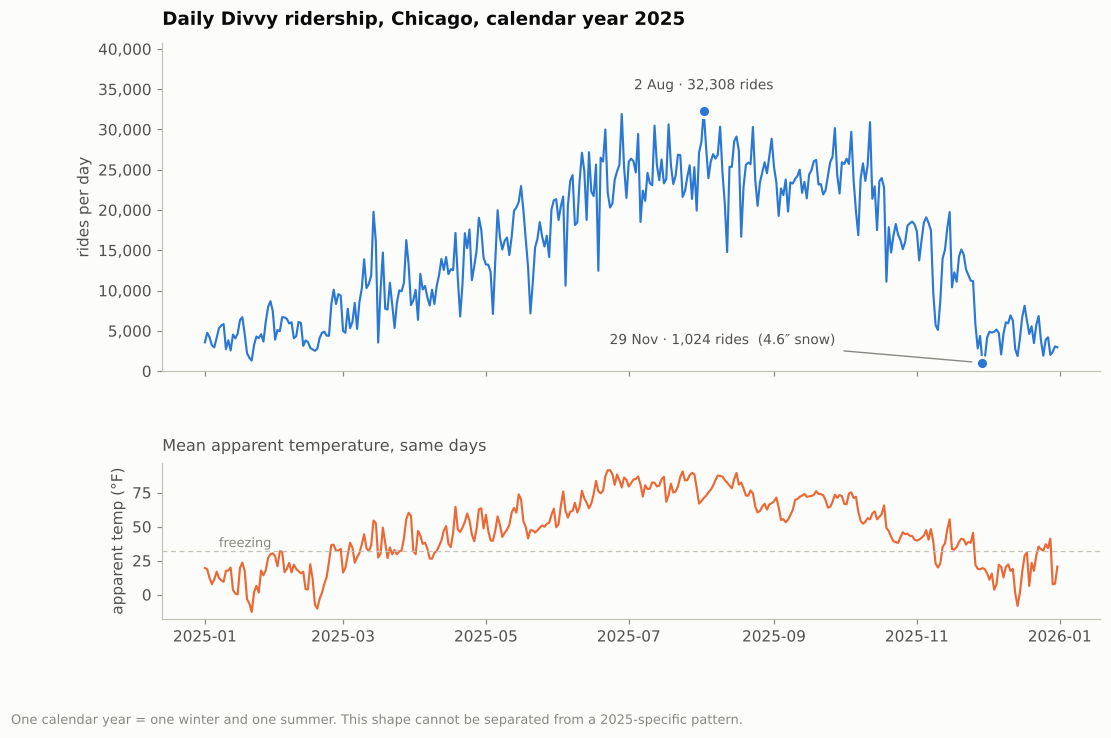

In [3]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 6.8), sharex=True,
                               gridspec_kw={"height_ratios":[2.1,1], "hspace":0.38})

ax1.plot(daily.date, daily.rides, color=S1, lw=1.4)
tidy(ax1); ax1.yaxis.set_major_formatter(thousands)
ax1.set_ylabel("rides per day")
ax1.set_ylim(0, daily.rides.max() * 1.26)
ax1.set_title("Daily Divvy ridership, Chicago, calendar year 2025")

hi = daily.loc[daily.rides.idxmax()]
lo = daily.loc[daily.rides.idxmin()]
for row in (hi, lo):
    ax1.plot(row.date, row.rides, "o", ms=8, color=S1,
             mec=SURFACE, mew=2, zorder=5)

ax1.annotate(f"{hi.date:%-d %b} \u00b7 {hi.rides:,} rides",
             (hi.date, hi.rides), xytext=(0, 12), textcoords="offset points",
             ha="center", va="bottom", fontsize=9, color=INK2)

# The 29 Nov snowstorm sits hard against the right edge, so it is called out
# into the empty band under the summer curve rather than labelled in place.
ax1.annotate(f"{lo.date:%-d %b} \u00b7 {lo.rides:,} rides  (4.6\u2033 snow)",
             (lo.date, lo.rides), xytext=(pd.Timestamp("2025-08-10"), 3800),
             textcoords="data", ha="center", va="center",
             fontsize=9, color=INK2,
             arrowprops=dict(arrowstyle="-", color=MUTED, lw=0.9,
                             shrinkA=4, shrinkB=7))

ax2.plot(daily.date, daily.apparent_temperature, color=S2, lw=1.4)
tidy(ax2); ax2.set_ylabel("apparent temp (\u00b0F)")
ax2.set_xlabel("")
ax2.set_title("Mean apparent temperature, same days", fontsize=10.5,
              color=INK2, fontweight="normal", pad=8)
ax2.axhline(32, color=AXIS, lw=0.8, ls=(0,(4,3)))
ax2.annotate("freezing", (daily.date.iloc[6], 35), fontsize=8.5, color=MUTED)

fig.text(0.0, -0.03,
         "One calendar year = one winter and one summer. This shape cannot be "
         "separated from a 2025-specific pattern.",
         fontsize=8.5, color=MUTED)
plt.show()

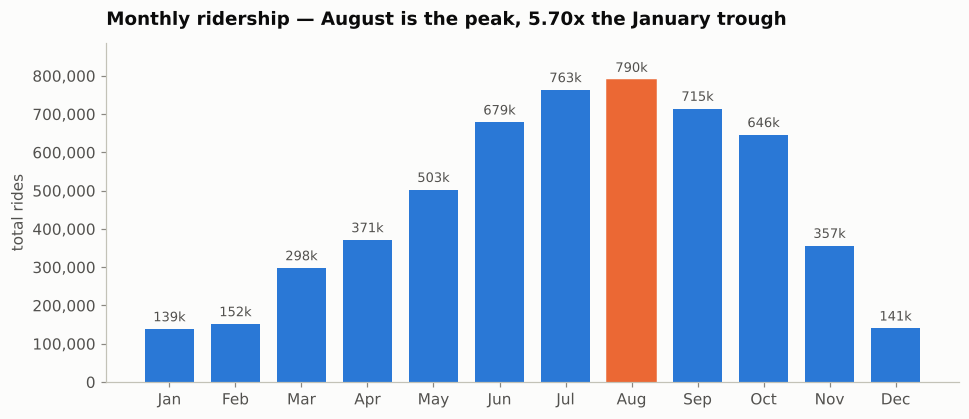

In [4]:
fig, ax = plt.subplots(figsize=(10, 4))
bars = ax.bar(tbl.month, tbl.rides, color=S1, width=0.74)
peak = int(tbl.rides.idxmax())
bars[peak].set_color(S2)
tidy(ax); ax.yaxis.set_major_formatter(thousands)
ax.set_ylabel("total rides")
ax.set_title("Monthly ridership — August is the peak, 5.70x the January trough")
for b, v in zip(bars, tbl.rides):
    ax.annotate(f"{v/1000:,.0f}k", (b.get_x()+b.get_width()/2, v), ha="center",
                va="bottom", fontsize=8.5, color=INK2, xytext=(0,3),
                textcoords="offset points")
ax.set_ylim(0, tbl.rides.max()*1.12)
plt.show()

the six commute hours (06-08, 16-18) carry 40.4% of all rides


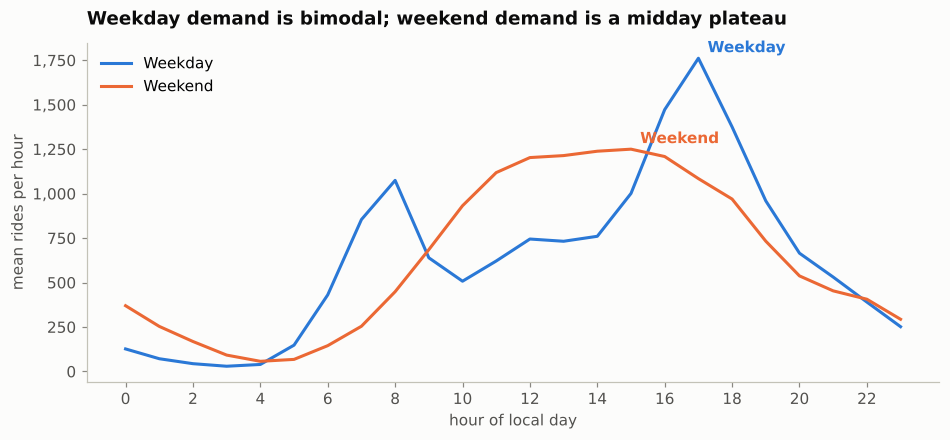

In [5]:
# Demand has two shapes, not one. This matters for what a daily total hides.
prof = (hourly.assign(kind=np.where(hourly.is_weekend, "Weekend", "Weekday"))
        .groupby(["kind","hour"]).rides.mean().reset_index())

fig, ax = plt.subplots(figsize=(10, 4))
for kind, col in (("Weekday", S1), ("Weekend", S2)):
    g = prof[prof.kind == kind]
    ax.plot(g.hour, g.rides, color=col, lw=2, label=kind)
    j = int(g.rides.idxmax())
    ax.annotate(kind, (g.hour[j], g.rides[j]), xytext=(6, 4),
                textcoords="offset points", color=col, fontsize=10,
                fontweight="bold")
tidy(ax); ax.yaxis.set_major_formatter(thousands)
ax.set_xlabel("hour of local day"); ax.set_ylabel("mean rides per hour")
ax.set_xticks(range(0, 24, 2))
ax.set_title("Weekday demand is bimodal; weekend demand is a midday plateau")
ax.legend(loc="upper left")
commute = hourly[hourly.hour.isin([6,7,8,16,17,18])].rides.sum() / hourly.rides.sum()
print(f"the six commute hours (06-08, 16-18) carry {100*commute:.1f}% of all rides")
plt.show()

---
## 3. Weather relationship

Apparent temperature is the single best predictor of daily ridership. The
response is **steeply increasing up to roughly 70 °F and then flat** — there is
no visible heat penalty in 2025 — so a linear temperature term will misfit the
top of the range. Use bins or a spline.

In [6]:
rows = []
for c in ["apparent_temperature","temperature_2m","temp_max","apparent_max",
          "relative_humidity_2m","precipitation","snowfall","cloud_cover",
          "wind_speed_10m"]:
    rows.append({"variable": c, "corr_with_daily_rides": daily.rides.corr(daily[c])})
cors = pd.DataFrame(rows).sort_values("corr_with_daily_rides", ascending=False)
display(cors.style.format({"corr_with_daily_rides":"{:+.3f}"}).hide(axis="index"))

print("Caution: wind and cloud cover correlate more strongly than precipitation,")
print("but in Chicago windy and overcast days ARE winter days. Those two are")
print("substantially season-confounded, not independent weather effects.")

variable,corr_with_daily_rides
apparent_temperature,+0.905
temperature_2m,+0.902
apparent_max,+0.891
temp_max,+0.887
relative_humidity_2m,-0.034
precipitation,-0.134
snowfall,-0.286
cloud_cover,-0.384
wind_speed_10m,-0.438


Caution: wind and cloud cover correlate more strongly than precipitation,
but in Chicago windy and overcast days ARE winter days. Those two are
substantially season-confounded, not independent weather effects.


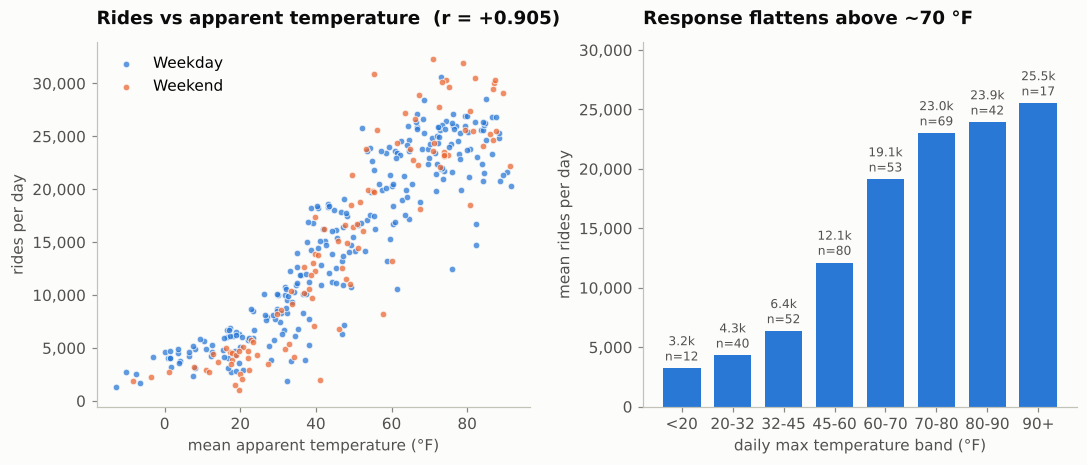

In [7]:
fig, (axa, axb) = plt.subplots(1, 2, figsize=(11.5, 4.3),
                               gridspec_kw={"wspace":0.26})

for kind, col in (("Weekday", S1), ("Weekend", S2)):
    g = daily[daily.is_weekend == (kind == "Weekend")]
    axa.scatter(g.apparent_temperature, g.rides, s=18, color=col,
                alpha=0.75, lw=0.6, edgecolors=SURFACE, label=kind)
tidy(axa); axa.yaxis.set_major_formatter(thousands)
axa.set_xlabel("mean apparent temperature (\u00b0F)")
axa.set_ylabel("rides per day")
axa.set_title(f"Rides vs apparent temperature  (r = "
              f"{daily.rides.corr(daily.apparent_temperature):+.3f})")
axa.legend(loc="upper left")

bins = [-100, 20, 32, 45, 60, 70, 80, 90, 200]
labs = ["<20","20-32","32-45","45-60","60-70","70-80","80-90","90+"]
daily["tband"] = pd.cut(daily.temp_max, bins=bins, labels=labs)
band = daily.groupby("tband", observed=True).rides.agg(["mean","size"]).reset_index()
bb = axb.bar(band.tband.astype(str), band["mean"], color=S1, width=0.74)
tidy(axb); axb.yaxis.set_major_formatter(thousands)
axb.set_xlabel("daily max temperature band (\u00b0F)")
axb.set_ylabel("mean rides per day")
axb.set_title("Response flattens above ~70 \u00b0F")
for b, v, n in zip(bb, band["mean"], band["size"]):
    axb.annotate(f"{v/1000:.1f}k\nn={n}", (b.get_x()+b.get_width()/2, v),
                 ha="center", va="bottom", fontsize=8, color=INK2,
                 xytext=(0,3), textcoords="offset points", linespacing=1.25)
axb.set_ylim(0, band["mean"].max()*1.2)
plt.show()

In [8]:
# Precipitation measured WITHIN month, so the season does not do the work.
rec = []
for m, g in daily.groupby("month"):
    wet, dry = g[g.precip_any], g[~g.precip_any]
    if len(wet) and len(dry):
        rec.append({"month": MONTHS[m-1], "dry_mean": dry.rides.mean(),
                    "wet_mean": wet.rides.mean(), "n_wet": len(wet),
                    "drop_%": 100*(1 - wet.rides.mean()/dry.rides.mean())})
wetdry = pd.DataFrame(rec)
display(wetdry.style.format({"dry_mean":"{:,.0f}","wet_mean":"{:,.0f}",
                             "drop_%":"{:+.1f}"}).hide(axis="index"))
print(f"mean within-month wet-day drop: {wetdry['drop_%'].mean():.1f}%")
print("February inverts (wet days busier) - small-sample artefact of a mild wet")
print("spell against a cold dry one, not a real effect.")

month,dry_mean,wet_mean,n_wet,drop_%
Jan,"4,704","3,987",10,+15.3
Feb,"5,000","5,915",13,-18.3
Mar,"10,281","8,811",14,+14.3
Apr,"13,213","11,546",15,+12.6
May,"17,175","14,882",13,+13.4
Jun,"24,114","20,927",14,+13.2
Jul,"26,455","23,308",18,+11.9
Aug,"26,555","23,814",12,+10.3
Sep,"24,195","22,582",7,+6.7
Oct,"21,878","17,288",7,+21.0


mean within-month wet-day drop: 11.9%
February inverts (wet days busier) - small-sample artefact of a mild wet
spell against a cold dry one, not a real effect.


---
## 4. Weather merge — verified, not assumed

**This section is the one to read before we go further.** The merge in
`dataframe_merger.ipynb` joins Divvy's local Chicago timestamps straight onto the
Open-Meteo export — and that export was pulled in **GMT**
(`utc_offset_seconds: 0`). The join still matches 100 % of rows and raises
nothing, so nothing in the notebook's output tells you it is wrong.

Below, the same weather file is merged both ways and the two results compared.

In [9]:
wx_raw = pd.read_excel("data/open-meteo_chicago.xlsx", skiprows=3)
meta = pd.read_excel("data/open-meteo_chicago.xlsx", header=None, nrows=2)
print("header block of the committed export:")
display(meta)

wx_raw = wx_raw[["time","temperature_2m (\u00b0C)","rain (mm)","snowfall (cm)",
                 "wind_speed_10m (km/h)"]]
wx_raw.columns = ["time","temp_c","rain_mm","snow_cm","wind_kmh"]
wx_raw["time"] = pd.to_datetime(wx_raw["time"])

rides_h = hourly[["hour_local","rides","is_weekend"]].copy()

# (a) as the notebook does it: GMT labels treated as local wall clock
naive = rides_h.merge(wx_raw, left_on="hour_local", right_on="time", how="left")

# (b) correct: label as UTC, convert to Chicago, collapse the doubled DST hour
w = wx_raw.copy()
w["hour_local"] = (w["time"].dt.tz_localize("UTC")
                   .dt.tz_convert("America/Chicago").dt.tz_localize(None))
w = w.groupby("hour_local", as_index=False)[["temp_c","rain_mm","snow_cm",
                                             "wind_kmh"]].mean()
right = rides_h.merge(w, on="hour_local", how="left")

print(f"\nrows out of the naive merge   : {len(naive):,}  "
      f"unmatched: {naive.temp_c.isna().sum()}")
print(f"rows out of the correct merge : {len(right):,}  "
      f"unmatched: {right.temp_c.isna().sum()}")
print("\nBoth 'succeed'. Row counts and null counts do not detect this error.")

header block of the committed export:


,0,1,2,3,4,5
0,latitude,longitude,elevation,utc_offset_seconds,timezone,timezone_abbreviation
1,41.8629,-87.6488,183,0,GMT,GMT



rows out of the naive merge   : 8,759  unmatched: 0
rows out of the correct merge : 8,759  unmatched: 6

Both 'succeed'. Row counts and null counts do not detect this error.


In [10]:
cmp = (naive[["hour_local","rides","temp_c"]]
       .merge(right[["hour_local","temp_c"]], on="hour_local",
              suffixes=("_naive","_correct")))
cmp["err"] = cmp.temp_c_naive - cmp.temp_c_correct

print("TEMPERATURE ATTACHED TO THE SAME RIDE-HOUR")
print(f"  mean absolute error      {cmp.err.abs().mean():.2f} \u00b0C")
print(f"  worst single hour        {cmp.err.abs().max():.1f} \u00b0C")
print(f"  hours wrong by >5 \u00b0C     {(cmp.err.abs()>5).sum():,} "
      f"({100*(cmp.err.abs()>5).mean():.1f}% of the year)")
print()
print("WHAT IT COSTS IN SIGNAL")
print(f"  hourly corr(temp, rides), naive    {cmp[['rides','temp_c_naive']].corr().iloc[0,1]:+.4f}")
print(f"  hourly corr(temp, rides), correct  {cmp[['rides','temp_c_correct']].corr().iloc[0,1]:+.4f}")
dd = (cmp.assign(date=cmp.hour_local.dt.date).groupby("date")
      .agg(rides=("rides","sum"), tn=("temp_c_naive","mean"),
           tc=("temp_c_correct","mean")))
print(f"  daily  corr(temp, rides), naive    {dd[['rides','tn']].corr().iloc[0,1]:+.4f}")
print(f"  daily  corr(temp, rides), correct  {dd[['rides','tc']].corr().iloc[0,1]:+.4f}")
print()
print("COVERAGE, which the naive merge also hides")
print(f"  export labelled   {wx_raw.time.min()} -> {wx_raw.time.max()} (GMT)")
print(f"  real local cover  {w.hour_local.min()} -> {w.hour_local.max()}")
print(f"  local 2025 hours left with no weather: {right.temp_c.isna().sum()} "
      "(the last evening of the year)")

TEMPERATURE ATTACHED TO THE SAME RIDE-HOUR
  mean absolute error      2.58 °C
  worst single hour        14.5 °C
  hours wrong by >5 °C     1,103 (12.6% of the year)

WHAT IT COSTS IN SIGNAL
  hourly corr(temp, rides), naive    +0.4968
  hourly corr(temp, rides), correct  +0.5853
  daily  corr(temp, rides), naive    +0.8951
  daily  corr(temp, rides), correct  +0.9020

COVERAGE, which the naive merge also hides
  export labelled   2025-01-01 00:00:00 -> 2025-12-31 23:00:00 (GMT)
  real local cover  2024-12-31 18:00:00 -> 2025-12-31 17:00:00
  local 2025 hours left with no weather: 6 (the last evening of the year)


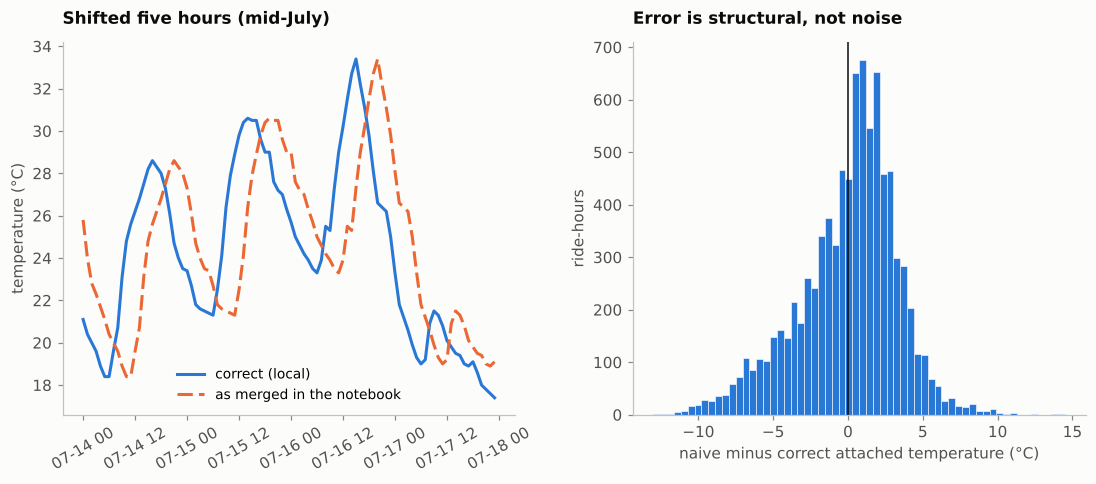

In [11]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.4),
                               gridspec_kw={"wspace":0.26})

wk = cmp[(cmp.hour_local >= "2025-07-14") & (cmp.hour_local < "2025-07-18")]
ax1.plot(wk.hour_local, wk.temp_c_correct, color=S1, lw=2, label="correct (local)")
ax1.plot(wk.hour_local, wk.temp_c_naive, color=S2, lw=2, ls=(0,(5,2)),
         label="as merged in the notebook")
tidy(ax1)
ax1.set_ylabel("temperature (\u00b0C)")
ax1.set_title("Shifted five hours (mid-July)", fontsize=11)
ax1.legend(loc="lower center", fontsize=9)
ax1.tick_params(axis="x", labelrotation=30)

ax2.hist(cmp.err, bins=60, color=S1, edgecolor=SURFACE, lw=0.4)
tidy(ax2)
ax2.set_xlabel("naive minus correct attached temperature (\u00b0C)")
ax2.set_ylabel("ride-hours")
ax2.set_title("Error is structural, not noise", fontsize=11)
ax2.axvline(0, color=INK, lw=1)
plt.show()

**Verification applied in `build_dataset.py`:**

* weather requested with `timezone=UTC` and converted with
  `tz_convert("America/Chicago")`, so local time is reproduced by construction;
* the range is padded a day either side, so the local year is fully covered;
* `2025-03-09 02:00` is confirmed absent (spring forward) and Divvy logs no rides
  in that hour; `2025-11-02 01:00` is confirmed to occur twice (fall back) and is
  collapsed to its mean, matching how Divvy's `started_at` labels both hours;
* the merge runs with `indicator=True` and **asserts zero unmatched ride-hours**,
  so a future re-run fails loudly instead of silently.

---
## 5. Data-quality summary

Everything below is reproduced by `build_dataset.py`, which writes it to
`data/merge_report.txt` on every run.

In [12]:
print(open("data/merge_report.txt").read())

=== DIVVY TRIPS ===
  months requested: 202501,202502,202503,202504,202505,202506,202507,202508,202509,202510,202511,202512
  raw rows read                5,552,994
  duplicate ride_id                    0
  start month != file month        1,075  (keyed on started_at, so handled correctly)
  rides outside CY2025                53  -> excluded: {datetime.date(2024, 12, 31): 53}
  rides in CY2025              5,552,941
  non-positive duration               29  (flagged, retained)
  null duration                        0
  local hour buckets               8,758
  distinct local dates               365

=== WEATHER (Open-Meteo ERA5 archive) ===
  rows pulled (UTC, padded)        8,808
  nulls across all variables           0
  DST fall-back doubled hour  ['2025-11-02 01:00:00']
  DST spring-forward missing  ['2025-03-09 02:00:00']
  unique local 2025 hours          8,759

=== MERGE VERIFICATION ===
  both          8758
  left_only        0
  right_only       1
  every ride-hour has weathe

In [13]:
qa = pd.DataFrame([
 ("Divvy trips",     "raw rows across 12 CY2025 archives", "5,552,994"),
 ("Divvy trips",     "excluded: started_at on 2024-12-31", "53"),
 ("Divvy trips",     "rides in scope (CY2025, local start date)", "5,552,941"),
 ("Divvy trips",     "duplicate ride_id", "0"),
 ("Divvy trips",     "start month differs from file month (handled)", "1,075"),
 ("Divvy trips",     "ended_at <= started_at (flagged, retained)", "29"),
 ("Divvy trips",     "blank station name/id (dockless e-bikes; unused)", "~33.5%"),
 ("Divvy trips",     "days covered / days with zero rides", "365 / 0"),
 ("Weather",         "source", "Open-Meteo ERA5 archive"),
 ("Weather",         "grid point actually served", "41.8629 N, -87.6488 W, 241 m"),
 ("Weather",         "nulls across all 12 variables", "0"),
 ("Weather",         "units", "\u00b0F, inch, mph, %, WMO code"),
 ("Merge",           "ride-hours matched / unmatched", "8,758 / 0"),
 ("Merge",           "weather hours with no rides", "1 (2025-01-22 03:00, 0.7 \u00b0F)"),
 ("Merge",           "local hours in 2025 (DST-correct)", "8,759"),
 ("Known limitation","calendar years of history", "1"),
 ("Known limitation","fleet size / pricing / station history", "not available"),
], columns=["area","check","value"])
display(qa.style.hide(axis="index"))

area,check,value
Divvy trips,raw rows across 12 CY2025 archives,"5,552,994"
Divvy trips,excluded: started_at on 2024-12-31,53
Divvy trips,"rides in scope (CY2025, local start date)","5,552,941"
Divvy trips,duplicate ride_id,0
Divvy trips,start month differs from file month (handled),"1,075"
Divvy trips,"ended_at <= started_at (flagged, retained)",29
Divvy trips,blank station name/id (dockless e-bikes; unused),~33.5%
Divvy trips,days covered / days with zero rides,365 / 0
Weather,source,Open-Meteo ERA5 archive
Weather,grid point actually served,"41.8629 N, -87.6488 W, 241 m"


### Limits we state without being asked

* **One calendar year is one winter and one summer.** Nothing in this dataset can
  separate a seasonal pattern from a 2025-specific one. The August peak may be
  climate, an event calendar, or a fleet or pricing change — this data cannot
  tell them apart.
* **No fleet-size, pricing, station-count or rebalancing history**, so any
  system-side change is invisible and will be absorbed into the weather and trend
  terms.
* **ERA5 is a ~9 km reanalysis grid, not a gauge at a station.** Internally
  consistent, but it will not match a specific Chicago observation exactly.
* **The seven-day outlook must use *forecast* weather**, which is less accurate
  than the archive the model trains on. Expect live error to exceed holdout
  error.

---
## 6. Baseline plan

The brief suggests "the same weekday in the previous week" as the baseline. On
2025 that baseline is **weak**, and beating it would flatter us.

In [14]:
d = daily.copy()
d["lag1"] = d.rides.shift(1)
d["lag7"] = d.rides.shift(7)

def score(y, p, label):
    m = p.notna()
    y, p = y[m], p[m]
    return {"baseline": label, "n": int(m.sum()),
            "MAE": np.abs(y-p).mean(), "RMSE": np.sqrt(((y-p)**2).mean()),
            "MAPE_%": 100*np.abs((y-p)/y).mean(), "bias": (p-y).mean()}

full = pd.DataFrame([score(d.rides, d.lag1, "lag-1 (yesterday)"),
                     score(d.rides, d.lag7, "lag-7 (same weekday last week)")])
print("FULL YEAR 2025")
display(full.style.format({"MAE":"{:,.0f}","RMSE":"{:,.0f}","MAPE_%":"{:.1f}",
                           "bias":"{:+,.0f}"}).hide(axis="index"))

print("Autocorrelation of daily rides")
for L in (1, 2, 3, 7, 14, 28):
    print(f"  lag {L:>2}   {d.rides.autocorr(L):.3f}")
print("\nlag-1 (0.915) beats lag-7 (0.865): day-to-day weather persistence")
print("dominates weekly seasonality at daily citywide scale.")

FULL YEAR 2025


baseline,n,MAE,RMSE,MAPE_%,bias
lag-1 (yesterday),364,"2,538","3,511",23.6,+2
lag-7 (same weekday last week),358,"3,245","4,402",36.7,+21


Autocorrelation of daily rides
  lag  1   0.915
  lag  2   0.872
  lag  3   0.853
  lag  7   0.865
  lag 14   0.846
  lag 28   0.718

lag-1 (0.915) beats lag-7 (0.865): day-to-day weather persistence
dominates weekly seasonality at daily citywide scale.


In [15]:
HOLD = pd.Timestamp("2025-11-06")          # last 8 weeks
tr, ho = d[d.date < HOLD], d[d.date >= HOLD]
print(f"train   {tr.date.min():%d %b} - {tr.date.max():%d %b}  ({len(tr)} days, "
      f"mean {tr.rides.mean():,.0f} rides/day)")
print(f"holdout {ho.date.min():%d %b} - {ho.date.max():%d %b}  ({len(ho)} days, "
      f"mean {ho.rides.mean():,.0f} rides/day)")

hold = pd.DataFrame([score(ho.rides, ho.lag1, "lag-1 (yesterday)"),
                     score(ho.rides, ho.lag7, "lag-7 (same weekday last week)")])
print("\nON THE 8-WEEK CHRONOLOGICAL HOLDOUT")
display(hold.style.format({"MAE":"{:,.0f}","RMSE":"{:,.0f}","MAPE_%":"{:.1f}",
                           "bias":"{:+,.0f}"}).hide(axis="index"))

train   01 Jan - 05 Nov  (309 days, mean 16,637 rides/day)
holdout 06 Nov - 31 Dec  (56 days, mean 7,360 rides/day)

ON THE 8-WEEK CHRONOLOGICAL HOLDOUT


baseline,n,MAE,RMSE,MAPE_%,bias
lag-1 (yesterday),56,"1,903","2,612",40.4,+288
lag-7 (same weekday last week),56,"3,542","5,005",92.3,"+1,808"


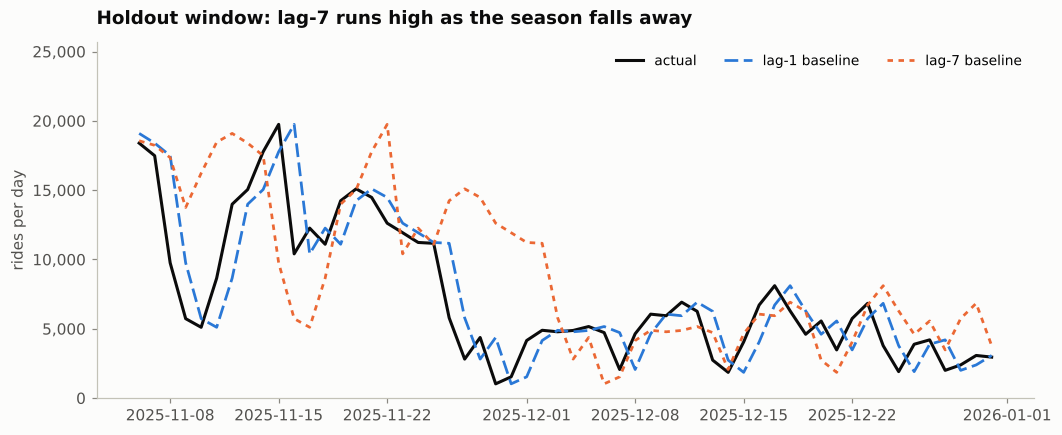

lag-7 bias over the holdout: +1,808 rides/day.
In a steeply declining season, last week's same weekday is systematically
too high. lag-1 is near-unbiased by comparison.


In [16]:
fig, ax = plt.subplots(figsize=(11, 4.2))
ax.plot(ho.date, ho.rides, color=INK, lw=2, label="actual")
ax.plot(ho.date, ho.lag1, color=S1, lw=1.8, ls=(0,(5,2)), label="lag-1 baseline")
ax.plot(ho.date, ho.lag7, color=S2, lw=1.8, ls=(0,(2,2)), label="lag-7 baseline")
tidy(ax); ax.yaxis.set_major_formatter(thousands)
ax.set_ylabel("rides per day")
ax.set_ylim(0, ho[["rides","lag1","lag7"]].max().max() * 1.3)
ax.set_title("Holdout window: lag-7 runs high as the season falls away")
ax.legend(loc="upper right", ncol=3, fontsize=9)
ax.tick_params(axis="x", labelrotation=0)
plt.show()

print(f"lag-7 bias over the holdout: {hold.loc[1,'bias']:+,.0f} rides/day.")
print("In a steeply declining season, last week's same weekday is systematically")
print("too high. lag-1 is near-unbiased by comparison.")

In [17]:
d["season"] = np.where(d.month.isin([5,6,7,8,9,10]), "high (May-Oct)",
                       "low (Nov-Apr)")
rec = []
for s, g in d.groupby("season"):
    m = g.lag1.notna()
    rec.append({"season": s, "days": int(m.sum()),
                "mean_rides": g.rides.mean(),
                "lag1_MAE": np.abs(g.rides[m]-g.lag1[m]).mean(),
                "lag1_MAPE_%": 100*np.abs((g.rides[m]-g.lag1[m])/g.rides[m]).mean()})
display(pd.DataFrame(rec).style.format({
    "mean_rides":"{:,.0f}","lag1_MAE":"{:,.0f}","lag1_MAPE_%":"{:.1f}"
}).hide(axis="index"))

print("MAPE is the wrong headline metric here. The same absolute error is 15.5%")
print("in high season and 32.0% in low season purely because the denominator")
print("collapses in winter. We lead with MAE and RMSE and report both seasons.")

season,days,mean_rides,lag1_MAE,lag1_MAPE_%
high (May-Oct),184,"22,260","3,075",15.5
low (Nov-Apr),180,"8,050","1,989",32.0


MAPE is the wrong headline metric here. The same absolute error is 15.5%
in high season and 32.0% in low season purely because the denominator
collapses in winter. We lead with MAE and RMSE and report both seasons.


### The plan we are taking into Tuesday 24 November

**Baselines to report — both, always.**

| baseline | full-year MAE | holdout MAE | why it is in the table |
|---|---|---|---|
| lag-7, same weekday last week | 3,245 | 3,542 | the brief's suggestion; the easy bar |
| **lag-1, yesterday** | **2,538** | **1,903** | the honest bar — persistence is strong here |

A model that beats 3,245 but not 2,538 has not beaten persistence, and we will
say so in those words.

**Validation design.** Chronological only. The 8-week year-end holdout above is
the headline, but it is **low season only** — mean 7,360 rides/day against 16,637
in training — so on its own it tests one regime. We will therefore *also* run a
**rolling-origin backtest** (expanding window, 7-day-ahead origin stepped through
the year) and report MAE by season. No random splits anywhere.

**Leakage rules, fixed now.**
* Predictors must exist at forecast issue time. Weather enters as *forecast*
  weather, never as the realised value for the target day.
* Lag features use completed days only: `lag1` for a 1-day-ahead origin means
  yesterday relative to the *origin*, not relative to the target.
* The seven-day outlook uses the live Open-Meteo forecast endpoint, with the
  issue date stated on the chart.

**First model family.** Gradient-boosted trees on: apparent temperature
(**binned or splined, not linear** — the response flattens above 70 °F),
precipitation, snowfall, wind, day-of-week, month, a holiday flag, and lag-1 /
lag-7 ride counts. A regularised linear model with the same features runs beside
it as the interpretable comparison.

**Open decisions for today's session**

1. **Clustering unit.** Station usage profiles are the forecast-safe option —
   clusters built from realised ridership cannot be assigned to a future date.
   Station fields are blank on ~33.5 % of rides (dockless e-bikes), so that
   subset needs a documented rule before we cluster.
2. **One canonical weather file.** The repo holds a 4-variable °C GMT export;
   `build_dataset.py` pulls 12 variables in °F with correct DST handling. Keep
   the old export *only* as the audit exhibit this notebook needs, and mark it
   deprecated in `data_description.md` so nobody merges against it by accident.
3. **Dashboard tool.** Streamlit reads straight from these CSVs and needs no
   publishing step; Tableau is easier to demo live. Pick one today so the draft
   can be built by 1 December.